# 8. Tujuan 4: dampak PM2.5 terhadap kesehatan

Regresi quasi-Poisson per rumah sakit dengan spline waktu 7 derajat bebas per tahun, lalu digabung dengan meta-analisis efek acak. Termasuk efek jeda dan kontrol negatif (PM2.5 hari berikutnya), uji sensitivitas empat spesifikasi model, perbandingan balita dan lansia, serta dampak episode asap dan kasus berlebih.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from patsy import dmatrix
from scipy.stats import norm

warnings.filterwarnings("ignore")

In [3]:
MART = "../data/mart/"
OUT = "../hasil/"

OUTCOME = {
    "resp_admissions_under5": "Balita (ISPA)",
    "resp_admissions_over60": "Lansia (gangguan pernapasan)",
    "asthma_emergency_cases": "Asma darurat",
    "copd_admissions": "PPOK",
    "cvd": "Kardiovaskular",
    "death": "Kematian",
    "resp": "Pernapasan umum",
}
DF_WAKTU = 21

In [4]:
dim = pd.read_csv(MART + "dim_lokasi.csv")[["stasiun", "hospital_id", "kategori_lokasi", "pulau", "wilayah_gambut"]]
sehat = pd.read_csv(MART + "fakta_kesehatan_harian.csv", parse_dates=["tanggal"])
sehat = sehat[sehat["dipakai_analisis_dampak"]].copy()
udara = pd.read_csv(MART + "fakta_udara_harian.csv", parse_dates=["tanggal"])
pm = udara.pivot(index="tanggal", columns="stasiun", values="pm25")

In [5]:
def siapkan(hid, stasiun):
    d = sehat[sehat["hospital_id"] == hid].sort_values("tanggal").set_index("tanggal")
    s = pm[stasiun].reindex(d.index)
    full = pm[stasiun]
    for l in range(0, 8):
        d[f"lag{l}"] = full.shift(l).reindex(d.index)
    d["lead1"] = full.shift(-1).reindex(d.index)
    d["lead2"] = full.shift(-2).reindex(d.index)
    d["rata_0_2"] = full.rolling(3, min_periods=3).mean().reindex(d.index)
    d["rata_0_6"] = full.rolling(7, min_periods=5).mean().reindex(d.index)
    d["t"] = (d.index - pd.Timestamp("2024-01-01")).days
    d["dow"] = d.index.dayofweek
    d["bln"] = d.index.month
    d["ym"] = d.index.year * 100 + d.index.month
    d["temp_z"] = (d["temp_c"] - d["temp_c"].mean()) / (d["temp_c"].std() + 1e-9)
    d["rh_z"] = (d["rhum_pct"] - d["rhum_pct"].mean()) / (d["rhum_pct"].std() + 1e-9)
    return d

In [6]:
def basis(d, spek):
    kov = "C(dow) + temp_z + rh_z"
    if spek == "A":
        f = kov
    elif spek == "B":
        f = kov + " + C(bln)"
    elif spek == "C":
        f = kov + f" + cr(t, df={DF_WAKTU}, constraints='center')"
    elif spek == "D":
        f = kov + " + C(ym)"
    return np.asarray(dmatrix(f, d, return_type="dataframe"))

In [7]:
def fit(y, Xb, pmv, mask):
    X = np.column_stack([Xb[mask], pmv[mask]])
    m = sm.GLM(y[mask], X, family=sm.families.Poisson()).fit(scale="X2")
    return m.params[-1], m.bse[-1]

In [8]:
def fit_dua(y, Xb, p1, p2, mask):
    X = np.column_stack([Xb[mask], p1[mask], p2[mask]])
    m = sm.GLM(y[mask], X, family=sm.families.Poisson()).fit(scale="X2")
    return m.params[-2:], m.bse[-2:], m.cov_params()[-2:, -2:]

In [9]:
def gabung(b, s):
    b, s = np.asarray(b), np.asarray(s)
    w = 1 / s ** 2
    mu_f = (w * b).sum() / w.sum()
    Q = (w * (b - mu_f) ** 2).sum()
    k = len(b)
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (Q - (k - 1)) / c)
    ws = 1 / (s ** 2 + tau2)
    mu = (ws * b).sum() / ws.sum()
    se = np.sqrt(1 / ws.sum())
    i2 = max(0.0, (Q - (k - 1)) / Q) if Q > 0 else 0.0
    return mu, se, tau2, i2

In [10]:
def baris_rr(mu, se):
    return {"rr": np.exp(mu), "rr_bawah": np.exp(mu - 1.96 * se), "rr_atas": np.exp(mu + 1.96 * se),
            "p_value": 2 * (1 - norm.cdf(abs(mu / se)))}


hos = dim[dim["hospital_id"].isin(sehat["hospital_id"].unique())].reset_index(drop=True)
data = {r.hospital_id: siapkan(r.hospital_id, r.stasiun) for r in hos.itertuples()}
basis_C = {h: basis(d, "C") for h, d in data.items()}
basis_lain = {sp: {h: basis(d, sp) for h, d in data.items()} for sp in ["A", "B", "D"]}

In [11]:
EKSPOSUR = [f"lag{l}" for l in range(8)] + ["lead1", "lead2", "rata_0_2", "rata_0_6"]
hasil_rs, hasil_lag = [], []
simpan = {}
for ex in EKSPOSUR:
    for o in OUTCOME:
        bs, ss = [], []
        for h, d in data.items():
            y = d[o].values.astype(float)
            pmv = d[ex].values / 10
            mask = ~np.isnan(pmv)
            if mask.sum() < 300:
                continue
            b, s = fit(y, basis_C[h], pmv, mask)
            bs.append(b)
            ss.append(s)
            simpan[("C", ex, o, h)] = (b, s)
            if ex == "lag0":
                hasil_rs.append({"hospital_id": h, "outcome": o, **baris_rr(b, s)})
        mu, se, tau2, i2 = gabung(bs, ss)
        hasil_lag.append({"outcome": o, "paparan": ex, "n_rs": len(bs), **baris_rr(mu, se), "i2_pct": round(i2 * 100)})
hasil_lag = pd.DataFrame(hasil_lag)

In [12]:
hasil_sens = []
for sp in ["A", "B", "C", "D"]:
    for o in OUTCOME:
        bs, ss = [], []
        for h, d in data.items():
            y = d[o].values.astype(float)
            pmv = d["lag0"].values / 10
            mask = ~np.isnan(pmv)
            if mask.sum() < 300:
                continue
            Xb = basis_C[h] if sp == "C" else basis_lain[sp][h]
            b, s = fit(y, Xb, pmv, mask)
            simpan[(sp, "lag0", o, h)] = (b, s)
            bs.append(b)
            ss.append(s)
        mu, se, tau2, i2 = gabung(bs, ss)
        hasil_sens.append({"spesifikasi": sp, "outcome": o, "n_rs": len(bs), **baris_rr(mu, se), "i2_pct": round(i2 * 100)})
hasil_sens = pd.DataFrame(hasil_sens)

In [13]:
for o in OUTCOME:
    bs, ss = [], []
    for h, d in data.items():
        y = d[o].values.astype(float)
        pmv = d["lag0"].values / 10
        mask = (~np.isnan(pmv)) & (pmv <= 10)
        if mask.sum() < 300:
            continue
        b, s_ = fit(y, basis_C[h], pmv, mask)
        bs.append(b)
        ss.append(s_)
    mu, se, tau2, i2 = gabung(bs, ss)
    hasil_sens.loc[len(hasil_sens)] = {"spesifikasi": "C_PM100", "outcome": o, "n_rs": len(bs), **baris_rr(mu, se), "i2_pct": round(i2 * 100)}

In [14]:
rr_dbl = []
for sp, Bm in [("C", basis_C), ("B", basis_lain["B"])]:
    for o in OUTCOME:
        bs, ss = [], []
        for h, d in data.items():
            y = d[o].values.astype(float)
            pmv = np.log2(d["lag0"].clip(lower=1).values)
            mask = ~np.isnan(d["lag0"].values)
            b, s_ = fit(y, Bm[h], pmv, mask)
            bs.append(b)
            ss.append(s_)
        mu, se, tau2, i2 = gabung(bs, ss)
        rr_dbl.append({"spesifikasi": sp, "outcome": o, "n_rs": len(bs), **baris_rr(mu, se), "i2_pct": round(i2 * 100)})
rr_dbl = pd.DataFrame(rr_dbl)
rr_dbl["outcome_label"] = rr_dbl["outcome"].map(OUTCOME)

In [15]:
gabungan = []
for tambahan in ["lag1", "lag2", "lag3", "lag4", "lag5", "lead1", "lead2"]:
    for o in OUTCOME:
        b0, b1, v0, v1 = [], [], [], []
        for h, d in data.items():
            y = d[o].values.astype(float)
            p1 = d["lag0"].values / 10
            p2 = d[tambahan].values / 10
            mask = ~(np.isnan(p1) | np.isnan(p2))
            if mask.sum() < 300:
                continue
            par, bse, cov = fit_dua(y, basis_C[h], p1, p2, mask)
            b0.append(par[0]); b1.append(par[1]); v0.append(bse[0]); v1.append(bse[1])
        m0 = gabung(b0, v0)
        m1 = gabung(b1, v1)
        gabungan.append({"outcome": o, "paparan_tambahan": tambahan, "rr_lag0_setelah_kontrol": np.exp(m0[0]),
                         "rr_tambahan": np.exp(m1[0]), "tambahan_bawah": np.exp(m1[0] - 1.96 * m1[1]),
                         "tambahan_atas": np.exp(m1[0] + 1.96 * m1[1]), "p_tambahan": 2 * (1 - norm.cdf(abs(m1[0] / m1[1])))})
gabungan = pd.DataFrame(gabungan)

In [16]:
hasil_rs = pd.DataFrame(hasil_rs).merge(hos, on="hospital_id")
ring_pm = pd.DataFrame({h: {"pm25_rata2": d["lag0"].mean(), "pm25_sd": d["lag0"].std(), "pm25_maks": d["lag0"].max(),
                            "hari_ada_pm": int(d["lag0"].notna().sum())} for h, d in data.items()}).T.reset_index(names="hospital_id")
hasil_rs = hasil_rs.merge(ring_pm, on="hospital_id")
hasil_rs["outcome_label"] = hasil_rs["outcome"].map(OUTCOME)

strata = []
for kat, g in hasil_rs.groupby("kategori_lokasi"):
    for o in OUTCOME:
        s = g[g["outcome"] == o]
        b = np.log(s["rr"].values)
        se = (np.log(s["rr_atas"].values) - b) / 1.96
        if len(s) >= 2:
            mu, sef, _, i2 = gabung(b, se)
            strata.append({"kategori_lokasi": kat, "outcome": o, "n_rs": len(s), **baris_rr(mu, sef)})
strata = pd.DataFrame(strata)

In [17]:
beda = []
for sp in ["A", "B", "C", "D"]:
    d_, v_ = [], []
    for h in data:
        k1, k2 = (sp, "lag0", "resp_admissions_under5", h), (sp, "lag0", "resp_admissions_over60", h)
        if k1 in simpan and k2 in simpan:
            d_.append(simpan[k1][0] - simpan[k2][0])
            v_.append(np.sqrt(simpan[k1][1] ** 2 + simpan[k2][1] ** 2))
    mu, se, _, _ = gabung(d_, v_)
    n_balita = sum(1 for dd in d_ if dd > 0)
    beda.append({"spesifikasi": sp, "n_rs": len(d_), "selisih_log_rr_balita_minus_lansia": mu,
                 "rasio_rr_balita_per_lansia": np.exp(mu), "rasio_bawah": np.exp(mu - 1.96 * se), "rasio_atas": np.exp(mu + 1.96 * se),
                 "p_value": 2 * (1 - norm.cdf(abs(mu / se))), "rs_balita_lebih_tinggi": n_balita})
beda = pd.DataFrame(beda)

In [18]:
x = sehat[sehat["pm25"].notna()].copy()
x["dow"] = x["tanggal"].dt.dayofweek
x["bln"] = x["tanggal"].dt.month
x["temp_z"] = x.groupby("hospital_id")["temp_c"].transform(lambda s: (s - s.mean()) / (s.std() + 1e-9))
x["rh_z"] = x.groupby("hospital_id")["rhum_pct"].transform(lambda s: (s - s.mean()) / (s.std() + 1e-9))
SKEMA = {
    "Rentang PM2.5": ([0, 15, 25, 35, 50, 75, 100, 150, 250, 500, 5000],
                      ["<15", "15–25", "25–35", "35–50", "50–75", "75–100", "100–150", "150–250", "250–500", ">500"], "25–35"),
    "Kategori ISPU": ([0, 15.5, 55.4, 150.4, 250.4, 5000],
                      ["Baik", "Sedang", "Tidak Sehat", "Sangat Tidak Sehat", "Berbahaya"], "Sedang"),
}
dosis = []
for nama, (batas, label, ref) in SKEMA.items():
    x["kelas"] = pd.cut(x["pm25"], batas, labels=label)
    n_kelas = x.groupby("kelas", observed=True).agg(n_hari=("pm25", "size"), n_rs=("hospital_id", "nunique"))
    hd = pd.get_dummies(x["hospital_id"], drop_first=True).astype(float)
    bd = pd.get_dummies(x["bln"], prefix="b", drop_first=True).astype(float)
    dd = pd.get_dummies(x["dow"], prefix="d", drop_first=True).astype(float)
    kd = pd.get_dummies(x["kelas"]).drop(columns=ref).astype(float)
    X = sm.add_constant(pd.concat([kd, hd, bd, dd, x[["temp_z", "rh_z"]]], axis=1)).astype(float)
    for o in OUTCOME:
        m = sm.GLM(x[o].values, X.values, family=sm.families.Poisson()).fit(scale="X2")
        par = pd.Series(m.params, index=X.columns)
        bse = pd.Series(m.bse, index=X.columns)
        for k in label:
            if k == ref:
                dosis.append({"skema": nama, "outcome": o, "kelas": k, "urutan": label.index(k), "rr": 1.0, "rr_bawah": 1.0, "rr_atas": 1.0,
                              "n_hari": int(n_kelas.loc[k, "n_hari"]), "n_rs": int(n_kelas.loc[k, "n_rs"]), "referensi": True})
            else:
                dosis.append({"skema": nama, "outcome": o, "kelas": k, "urutan": label.index(k), "rr": np.exp(par[k]),
                              "rr_bawah": np.exp(par[k] - 1.96 * bse[k]), "rr_atas": np.exp(par[k] + 1.96 * bse[k]),
                              "n_hari": int(n_kelas.loc[k, "n_hari"]), "n_rs": int(n_kelas.loc[k, "n_rs"]), "referensi": False})
dosis = pd.DataFrame(dosis)
dosis["outcome_label"] = dosis["outcome"].map(OUTCOME)

In [19]:
epi = pd.read_csv(MART + "hari_episode_asap.csv", parse_dates=["tanggal"])
epi["episode"] = 1
e = sehat.merge(epi[["stasiun", "tanggal", "id_episode", "episode"]], on=["stasiun", "tanggal"], how="left")
e["episode"] = e["episode"].fillna(0).astype(int)
rs_epi = e.loc[e["episode"] == 1, "hospital_id"].unique()
e = e[e["hospital_id"].isin(rs_epi)].copy()
e["dow"] = e["tanggal"].dt.dayofweek
e["bln"] = e["tanggal"].dt.month
e["tahun"] = e["tanggal"].dt.year
rr_epi, ex_rows = [], []
epi_b = {}
for o in OUTCOME:
    bs, ss, bs2, ss2 = [], [], [], []
    for h, g in e.groupby("hospital_id"):
        if g["episode"].sum() < 5:
            continue
        g = g.copy()
        g["temp_z"] = (g["temp_c"] - g["temp_c"].mean()) / (g["temp_c"].std() + 1e-9)
        g["rh_z"] = (g["rhum_pct"] - g["rhum_pct"].mean()) / (g["rhum_pct"].std() + 1e-9)
        X1 = dmatrix("episode + C(dow) + temp_z + rh_z", g, return_type="dataframe")
        X2 = dmatrix("episode + C(dow) + temp_z + rh_z + C(bln)", g, return_type="dataframe")
        m1 = sm.GLM(g[o].values, np.asarray(X1), family=sm.families.Poisson()).fit(scale="X2")
        m2 = sm.GLM(g[o].values, np.asarray(X2), family=sm.families.Poisson()).fit(scale="X2")
        i1, i2_ = list(X1.columns).index("episode"), list(X2.columns).index("episode")
        bs.append(m1.params[i1]); ss.append(m1.bse[i1]); bs2.append(m2.params[i2_]); ss2.append(m2.bse[i2_])
        epi_b[(o, "m1", h)] = (m1.params[i1], m1.bse[i1])
        epi_b[(o, "m2", h)] = (m2.params[i2_], m2.bse[i2_])
    for nama, (b, s) in {"Semua hari bukan episode": (bs, ss), "Bulan kalender yang sama": (bs2, ss2)}.items():
        mu, se, _, i2 = gabung(b, s)
        rr_epi.append({"outcome": o, "pembanding": nama, "n_rs": len(b), **baris_rr(mu, se), "i2_pct": round(i2 * 100)})
rr_epi = pd.DataFrame(rr_epi)
rr_epi["outcome_label"] = rr_epi["outcome"].map(OUTCOME)

In [20]:
beda_epi = []
for mod, nama in [("m1", "Semua hari bukan episode"), ("m2", "Bulan kalender yang sama")]:
    d_, v_ = [], []
    for h in rs_epi:
        k1, k2 = ("resp_admissions_under5", mod, h), ("resp_admissions_over60", mod, h)
        if k1 in epi_b and k2 in epi_b:
            d_.append(epi_b[k1][0] - epi_b[k2][0])
            v_.append(np.sqrt(epi_b[k1][1] ** 2 + epi_b[k2][1] ** 2))
    mu, se, _, _ = gabung(d_, v_)
    beda_epi.append({"pembanding": nama, "n_rs": len(d_), "rasio_rr_balita_per_lansia": np.exp(mu),
                     "bawah": np.exp(mu - 1.96 * se), "atas": np.exp(mu + 1.96 * se), "p_value": 2 * (1 - norm.cdf(abs(mu / se))),
                     "rs_balita_lebih_tinggi": int(sum(1 for dd in d_ if dd > 0))})
beda_epi = pd.DataFrame(beda_epi)

In [21]:
for (h, th), g in e.groupby(["hospital_id", "tahun"]):
    ep_g = g[g["episode"] == 1]
    non = e[(e["hospital_id"] == h) & (e["episode"] == 0)]
    if len(ep_g) == 0:
        continue
    for o in OUTCOME:
        base = non[o].mean()
        ex_rows.append({"hospital_id": h, "stasiun": g["stasiun"].iloc[0], "tahun": th, "outcome": o,
                        "hari_episode": len(ep_g), "kasus_episode": int(ep_g[o].sum()),
                        "rata2_hari_episode": ep_g[o].mean(), "rata2_hari_biasa": base,
                        "kasus_berlebih": ep_g[o].sum() - len(ep_g) * base,
                        "kenaikan_pct": (ep_g[o].mean() / base - 1) * 100})
excess = pd.DataFrame(ex_rows).merge(dim[["hospital_id", "kategori_lokasi", "pulau"]], on="hospital_id")
excess["outcome_label"] = excess["outcome"].map(OUTCOME)

In [22]:
ring_ex = excess.groupby(["tahun", "outcome", "outcome_label"]).agg(
    hari_rs_episode=("hari_episode", "sum"), kasus_episode=("kasus_episode", "sum"),
    kasus_berlebih=("kasus_berlebih", "sum")).reset_index()
ring_ex["kenaikan_pct"] = ring_ex["kasus_berlebih"] / (ring_ex["kasus_episode"] - ring_ex["kasus_berlebih"]) * 100
tot_ex = excess.groupby(["outcome", "outcome_label"]).agg(
    hari_rs_episode=("hari_episode", "sum"), kasus_episode=("kasus_episode", "sum"), kasus_berlebih=("kasus_berlebih", "sum")).reset_index()
tot_ex["kenaikan_pct"] = tot_ex["kasus_berlebih"] / (tot_ex["kasus_episode"] - tot_ex["kasus_berlebih"]) * 100

In [23]:
hasil_lag["outcome_label"] = hasil_lag["outcome"].map(OUTCOME)
hasil_sens["outcome_label"] = hasil_sens["outcome"].map(OUTCOME)
strata["outcome_label"] = strata["outcome"].map(OUTCOME)
gabungan["outcome_label"] = gabungan["outcome"].map(OUTCOME)

BATAS_OBS = [0, 25, 35, 50, 75, 100, 150, 250, 400, 600, 5000]
LABEL_OBS = ["<25", "25–35", "35–50", "50–75", "75–100", "100–150", "150–250", "250–400", "400–600", ">600"]
obs = []
for h, d in data.items():
    d = d.dropna(subset=["lag0"]).copy()
    d["kelas"] = pd.cut(d["lag0"], BATAS_OBS, labels=LABEL_OBS)
    ag = d.groupby("kelas", observed=True).agg(n_hari=("lag0", "size"), pm25_rata2=("lag0", "mean"), **{o: (o, "mean") for o in OUTCOME})
    ag = ag[ag["n_hari"] >= 15]
    if len(ag) < 3 or d["lag0"].std() < 15:
        continue
    ref = ag.iloc[0]
    for k, r in ag.iterrows():
        for o in OUTCOME:
            obs.append({"hospital_id": h, "stasiun": hos.set_index("hospital_id").loc[h, "stasiun"], "outcome": o, "kelas": k,
                        "urutan": LABEL_OBS.index(k), "pm25_rata2": r["pm25_rata2"], "n_hari": int(r["n_hari"]),
                        "kasus_rata2": r[o], "rasio_terhadap_rendah": r[o] / ref[o], "pm25_referensi": ref["pm25_rata2"]})
obs = pd.DataFrame(obs)
obs["outcome_label"] = obs["outcome"].map(OUTCOME)
obs.to_csv(MART + "fakta_dosis_respons_rs.csv", index=False)
rr_dbl.to_csv(MART + "fakta_rr_penggandaan.csv", index=False)

In [24]:
lag_num = {"lead2": -2, "lead1": -1, "lag0": 0, "lag1": 1, "lag2": 2, "lag3": 3, "lag4": 4, "lag5": 5, "lag6": 6, "lag7": 7}
lag_tab = hasil_lag.copy()
lag_tab["jenis_paparan"] = np.where(lag_tab["paparan"].isin(lag_num), "Harian tunggal", "Rata-rata bergerak")
lag_tab["jeda_hari"] = lag_tab["paparan"].map(lag_num)
lag_tab["label_paparan"] = lag_tab["paparan"].map({**{k: ("PM2.5 besok (kontrol negatif)" if k == "lead1" else "PM2.5 lusa (kontrol negatif)" if k == "lead2" else f"Lag {v} hari") for k, v in lag_num.items()},
                                                    "rata_0_2": "Rata-rata 0–2 hari", "rata_0_6": "Rata-rata 0–6 hari"})
lag_tab.to_csv(MART + "fakta_rr_lag.csv", index=False)
hasil_rs.to_csv(MART + "fakta_rr_rs.csv", index=False)
dosis.to_csv(MART + "fakta_dosis_respons.csv", index=False)
excess.to_csv(MART + "fakta_episode_dampak.csv", index=False)
hasil_sens.to_csv(MART + "fakta_rr_sensitivitas.csv", index=False)
strata.to_csv(MART + "fakta_rr_kategori_lokasi.csv", index=False)
gabungan.to_csv(MART + "fakta_rr_jeda_tambahan.csv", index=False)
beda.to_csv(MART + "fakta_balita_vs_lansia.csv", index=False)
beda_epi.to_csv(MART + "fakta_balita_vs_lansia_episode.csv", index=False)
rr_epi.to_csv(MART + "fakta_rr_episode.csv", index=False)

In [25]:
with pd.ExcelWriter(OUT + "07_T4_dampak_kesehatan.xlsx") as w:
    lag_tab.round(4).to_excel(w, sheet_name="rr_per_jeda", index=False)
    gabungan.round(4).to_excel(w, sheet_name="model_gabungan_jeda", index=False)
    hasil_sens.round(4).to_excel(w, sheet_name="sensitivitas_spesifikasi", index=False)
    rr_dbl.round(4).to_excel(w, sheet_name="rr_per_penggandaan_pm25", index=False)
    obs.round(3).to_excel(w, sheet_name="dosis_respons_per_rs", index=False)
    beda.round(4).to_excel(w, sheet_name="balita_vs_lansia", index=False)
    beda_epi.round(4).to_excel(w, sheet_name="balita_vs_lansia_episode", index=False)
    hasil_rs.round(4).to_excel(w, sheet_name="rr_per_rumah_sakit", index=False)
    strata.round(4).to_excel(w, sheet_name="rr_per_kategori_lokasi", index=False)
    dosis.round(4).to_excel(w, sheet_name="dosis_respons", index=False)
    rr_epi.round(4).to_excel(w, sheet_name="rr_episode", index=False)
    excess.round(2).to_excel(w, sheet_name="episode_per_rs_tahun", index=False)
    ring_ex.round(1).to_excel(w, sheet_name="episode_per_tahun", index=False)
    tot_ex.round(1).to_excel(w, sheet_name="episode_total", index=False)

In [26]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print("=== RR per +10 ug/m3 PM2.5 lag 0 (spesifikasi C, gabungan acak) ===")
print(hasil_lag[hasil_lag["paparan"] == "lag0"][["outcome_label", "n_rs", "rr", "rr_bawah", "rr_atas", "p_value", "i2_pct"]].round(3).to_string())
print("=== RR per jeda ===")
print(hasil_lag.pivot(index="paparan", columns="outcome_label", values="rr").loc[EKSPOSUR].round(3).to_string())
print("=== model gabungan ===")
print(gabungan.drop(columns="outcome_label").round(4).to_string())
print("=== penggandaan ===")
print(rr_dbl.round(3).to_string())
print("=== sensitivitas ===")
print(hasil_sens.pivot(index="outcome", columns="spesifikasi", values="rr").round(3).to_string())
print(hasil_sens[hasil_sens["spesifikasi"] == "C_PM100"].round(3).to_string())
print("=== balita vs lansia ===")
print(beda.round(4).to_string())
print(beda_epi.round(4).to_string())
print("=== strata kategori lokasi (lag0, ISPA balita) ===")
print(strata[strata["outcome"] == "resp_admissions_under5"].round(3).to_string())
print("=== RR episode ===")
print(rr_epi.round(3).to_string())
print("=== kasus berlebih total ===")
print(tot_ex.round(1).to_string())
print(ring_ex[ring_ex["outcome"].isin(["resp_admissions_under5", "death"])].round(1).to_string())
print("=== RR per RS ISPA balita lag0 ===")
print(hasil_rs[hasil_rs["outcome"] == "resp_admissions_under5"][["hospital_id", "stasiun", "kategori_lokasi", "pm25_rata2", "pm25_sd", "rr", "rr_bawah", "rr_atas", "p_value"]].round(3).to_string())
print("=== dosis respons ISPU ===")
print(dosis[dosis["skema"] == "Kategori ISPU"].pivot(index="kelas", columns="outcome_label", values="rr").round(2).to_string())

=== RR per +10 ug/m3 PM2.5 lag 0 (spesifikasi C, gabungan acak) ===
                  outcome_label  n_rs     rr  rr_bawah  rr_atas  p_value  i2_pct
0                 Balita (ISPA)    25  1.102     1.080    1.125      0.0      99
1  Lansia (gangguan pernapasan)    25  1.099     1.078    1.121      0.0      99
2                  Asma darurat    25  1.100     1.079    1.122      0.0      98
3                          PPOK    25  1.095     1.074    1.117      0.0      98
4                Kardiovaskular    25  1.031     1.024    1.037      0.0      85
5                      Kematian    25  1.044     1.031    1.056      0.0      83
6               Pernapasan umum    25  1.085     1.067    1.103      0.0      99
=== RR per jeda ===
outcome_label  Asma darurat  Balita (ISPA)  Kardiovaskular  Kematian  Lansia (gangguan pernapasan)   PPOK  Pernapasan umum
paparan                                                                                                                   
lag0              

## Gambar hasil Tujuan 4

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter

MART = "../data/mart/"
GAMBAR = "../hasil/gambar/"
WARNA_OUT = {"resp_admissions_under5": "#c62828", "resp_admissions_over60": "#1565c0", "asthma_emergency_cases": "#f9a825",
             "copd_admissions": "#6d4c41", "cvd": "#2e7d32", "death": "#212121", "resp": "#78909c"}
LABEL_OUT = {"resp_admissions_under5": "ISPA balita", "resp_admissions_over60": "Gangguan napas lansia", "asthma_emergency_cases": "Asma darurat",
             "copd_admissions": "PPOK", "cvd": "Kardiovaskular", "death": "Kematian", "resp": "Pernapasan umum"}
WARNA_KAT = {"Industri": "#6d4c41", "Gambut": "#c62828", "Perkotaan": "#1565c0", "Tepi Jalan": "#f9a825", "Latar Bersih": "#2e7d32"}
URUT = ["resp_admissions_under5", "resp_admissions_over60", "asthma_emergency_cases", "copd_admissions", "cvd", "death"]

In [28]:
lag = pd.read_csv(MART + "fakta_rr_lag.csv")
sens = pd.read_csv(MART + "fakta_rr_sensitivitas.csv")
tamb = pd.read_csv(MART + "fakta_rr_jeda_tambahan.csv")
rs = pd.read_csv(MART + "fakta_rr_rs.csv")
dos = pd.read_csv(MART + "fakta_dosis_respons_rs.csv")
epi = pd.read_csv(MART + "fakta_episode_dampak.csv")
rre = pd.read_csv(MART + "fakta_rr_episode.csv")
dim = pd.read_csv(MART + "dim_lokasi.csv")

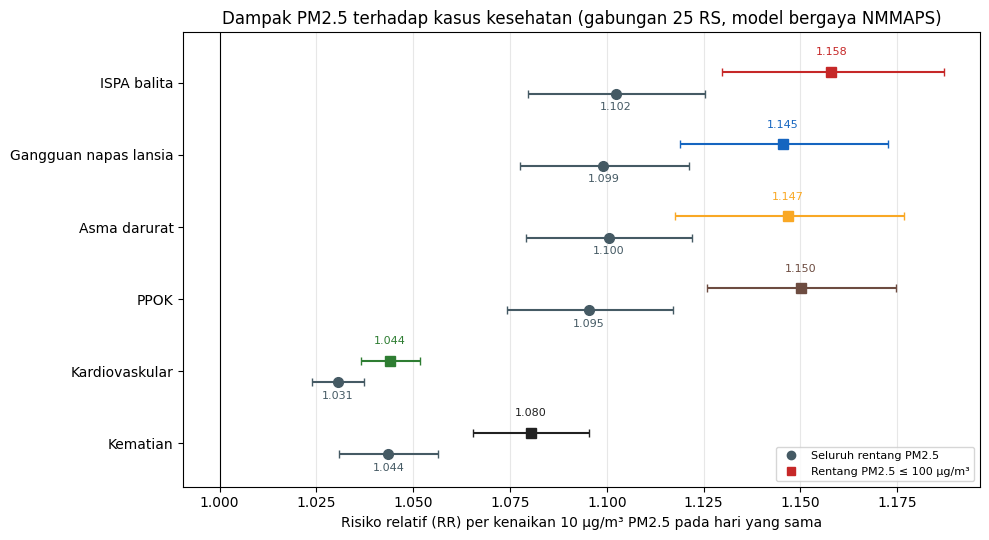

In [29]:
a = sens[(sens["spesifikasi"] == "C") & sens["outcome"].isin(URUT)].set_index("outcome").loc[URUT]
b = sens[(sens["spesifikasi"] == "C_PM100") & sens["outcome"].isin(URUT)].set_index("outcome").loc[URUT]
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(URUT))
for yy, o in zip(y, URUT):
    ax.errorbar(a.loc[o, "rr"], yy + 0.15, xerr=[[a.loc[o, "rr"] - a.loc[o, "rr_bawah"]], [a.loc[o, "rr_atas"] - a.loc[o, "rr"]]],
                fmt="o", color="#455a64", capsize=3, ms=7)
    ax.text(a.loc[o, "rr"], yy + 0.38, f"{a.loc[o, 'rr']:.3f}", ha="center", fontsize=8, color="#455a64")
    ax.errorbar(b.loc[o, "rr"], yy - 0.15, xerr=[[b.loc[o, "rr"] - b.loc[o, "rr_bawah"]], [b.loc[o, "rr_atas"] - b.loc[o, "rr"]]],
                fmt="s", color=WARNA_OUT[o], capsize=3, ms=7)
    ax.text(b.loc[o, "rr"], yy - 0.38, f"{b.loc[o, 'rr']:.3f}", ha="center", fontsize=8, color=WARNA_OUT[o])
ax.axvline(1, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([LABEL_OUT[o] for o in URUT])
ax.set_ylim(len(URUT) - 0.4, -0.7)
ax.set_xlabel("Risiko relatif (RR) per kenaikan 10 µg/m³ PM2.5 pada hari yang sama")
ax.set_title("Dampak PM2.5 terhadap kasus kesehatan (gabungan 25 RS, model bergaya NMMAPS)")
ax.legend(handles=[plt.Line2D([], [], marker="o", color="#455a64", ls=""), plt.Line2D([], [], marker="s", color="#c62828", ls="")],
          labels=["Seluruh rentang PM2.5", "Rentang PM2.5 ≤ 100 µg/m³"], loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "07_T4_rr_per_outcome.png", dpi=150)
plt.show()

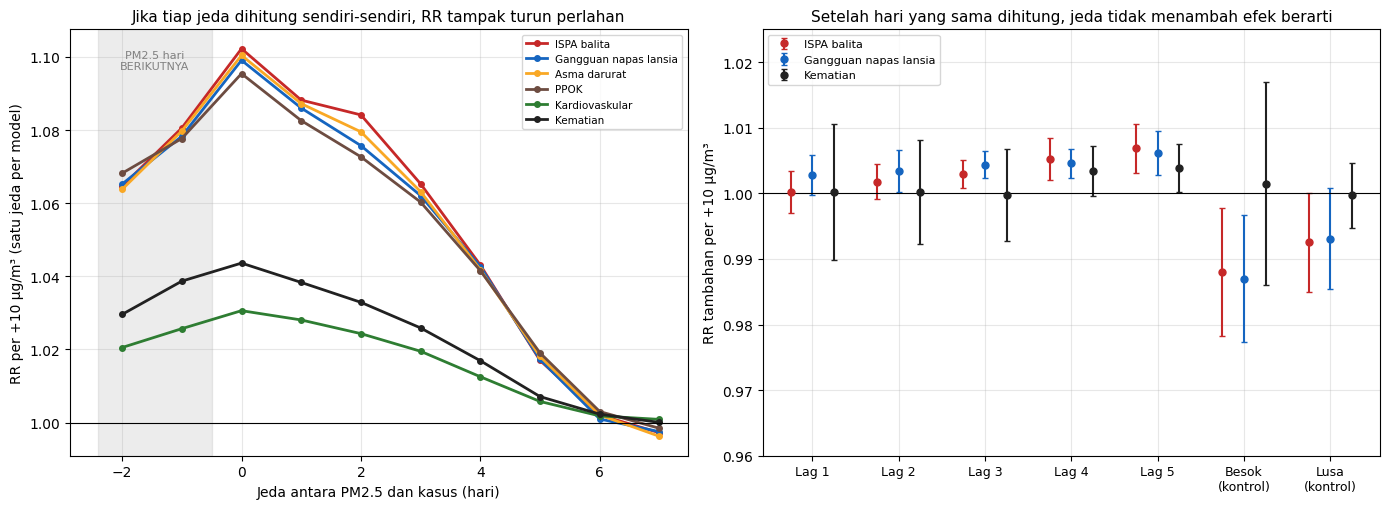

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
tunggal = lag[lag["jenis_paparan"] == "Harian tunggal"].sort_values("jeda_hari")
for o in URUT:
    t = tunggal[tunggal["outcome"] == o]
    axes[0].plot(t["jeda_hari"], t["rr"], marker="o", ms=4, lw=2, color=WARNA_OUT[o], label=LABEL_OUT[o])
axes[0].axvspan(-2.4, -0.5, color="grey", alpha=0.15)
axes[0].text(-1.45, axes[0].get_ylim()[1] * 0.995, "PM2.5 hari\nBERIKUTNYA", ha="center", va="top", fontsize=8, color="grey")
axes[0].axhline(1, color="black", lw=0.8)
axes[0].set_xlabel("Jeda antara PM2.5 dan kasus (hari)")
axes[0].set_ylabel("RR per +10 µg/m³ (satu jeda per model)")
axes[0].set_title("Jika tiap jeda dihitung sendiri-sendiri, RR tampak turun perlahan", fontsize=11)
axes[0].legend(fontsize=7.5)
axes[0].grid(alpha=0.3)
urut_t = ["lag1", "lag2", "lag3", "lag4", "lag5", "lead1", "lead2"]
nama_t = {"lag1": "Lag 1", "lag2": "Lag 2", "lag3": "Lag 3", "lag4": "Lag 4", "lag5": "Lag 5", "lead1": "Besok\n(kontrol)", "lead2": "Lusa\n(kontrol)"}
for i, o in enumerate(["resp_admissions_under5", "resp_admissions_over60", "death"]):
    t = tamb[tamb["outcome"] == o].set_index("paparan_tambahan").loc[urut_t]
    x = np.arange(len(urut_t)) + (i - 1) * 0.25
    axes[1].errorbar(x, t["rr_tambahan"], yerr=[t["rr_tambahan"] - t["tambahan_bawah"], t["tambahan_atas"] - t["rr_tambahan"]],
                     fmt="o", color=WARNA_OUT[o], capsize=2.5, ms=5, label=LABEL_OUT[o])
axes[1].axhline(1, color="black", lw=0.8)
axes[1].set_xticks(np.arange(len(urut_t)))
axes[1].set_xticklabels([nama_t[k] for k in urut_t], fontsize=9)
axes[1].set_ylim(0.96, 1.025)
axes[1].set_ylabel("RR tambahan per +10 µg/m³")
axes[1].set_title("Setelah hari yang sama dihitung, jeda tidak menambah efek berarti", fontsize=11)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "07_T4_efek_jeda.png", dpi=150)
plt.show()

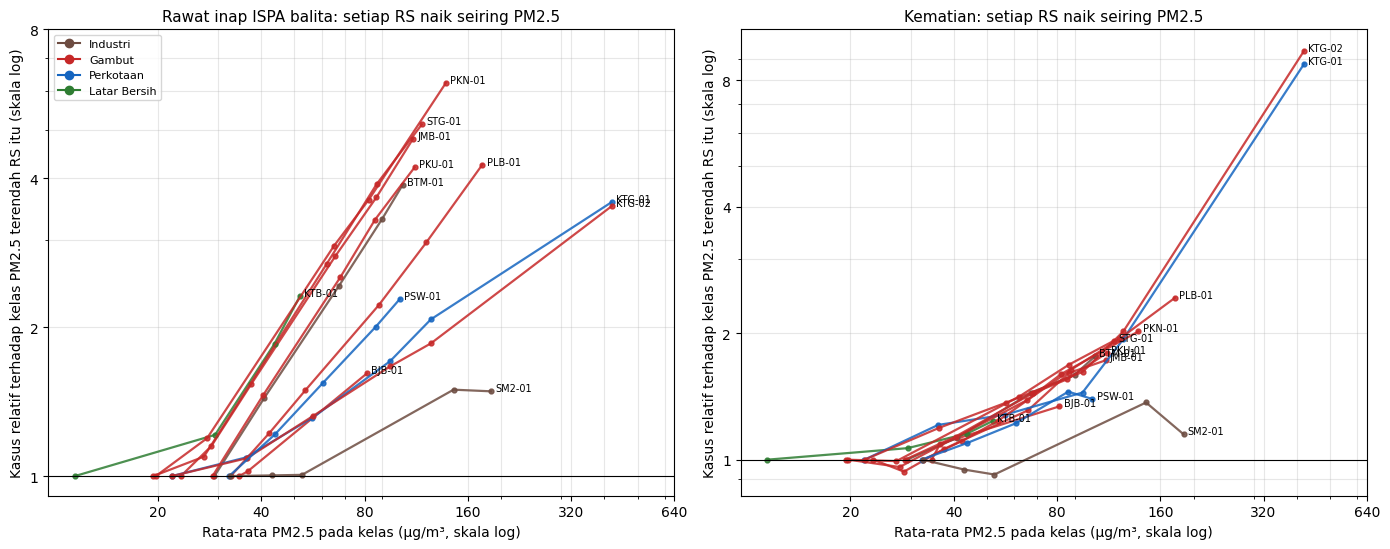

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
kat = dim.set_index("stasiun")["kategori_lokasi"]
for ax, o, judul in [(axes[0], "resp_admissions_under5", "Rawat inap ISPA balita"), (axes[1], "death", "Kematian")]:
    for st, g in dos[dos["outcome"] == o].groupby("stasiun"):
        g = g.sort_values("pm25_rata2")
        ax.plot(g["pm25_rata2"], g["rasio_terhadap_rendah"], marker="o", ms=3.5, lw=1.6, color=WARNA_KAT[kat[st]], alpha=0.85)
        ax.annotate(st, (g["pm25_rata2"].iloc[-1], g["rasio_terhadap_rendah"].iloc[-1]), fontsize=7, xytext=(3, 0), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks([20, 40, 80, 160, 320, 640])
    ax.set_xticklabels([20, 40, 80, 160, 320, 640])
    ax.set_yticks([1, 2, 4, 8])
    ax.set_yticklabels([1, 2, 4, 8])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.axhline(1, color="black", lw=0.8)
    ax.set_xlabel("Rata-rata PM2.5 pada kelas (µg/m³, skala log)")
    ax.set_ylabel("Kasus relatif terhadap kelas PM2.5 terendah RS itu (skala log)")
    ax.set_title(judul + ": setiap RS naik seiring PM2.5", fontsize=11)
    ax.grid(alpha=0.3, which="both")
ada = [k for k in WARNA_KAT if k in set(kat[dos["stasiun"].unique()])]
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="-", color=WARNA_KAT[k]) for k in ada], labels=ada, fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(GAMBAR + "07_T4_dosis_respons_rs.png", dpi=150)
plt.show()

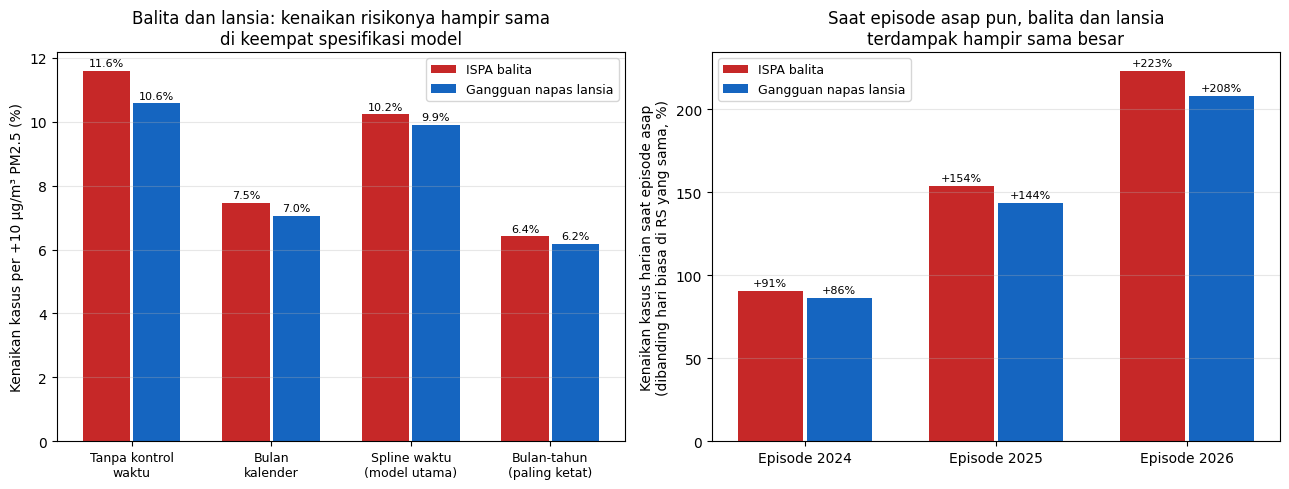

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
nm = {"A": "Tanpa kontrol\nwaktu", "B": "Bulan\nkalender", "C": "Spline waktu\n(model utama)", "D": "Bulan-tahun\n(paling ketat)"}
x = np.arange(4)
for i, (o, w) in enumerate([("resp_admissions_under5", "#c62828"), ("resp_admissions_over60", "#1565c0")]):
    t = sens[(sens["outcome"] == o) & sens["spesifikasi"].isin(["A", "B", "C", "D"])].set_index("spesifikasi").loc[["A", "B", "C", "D"]]
    axes[0].bar(x + (i - 0.5) * 0.36, (t["rr"] - 1) * 100, width=0.34, color=w, label=LABEL_OUT[o])
    for xx, v in zip(x + (i - 0.5) * 0.36, (t["rr"] - 1) * 100):
        axes[0].text(xx, v + 0.15, f"{v:.1f}%", ha="center", fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels([nm[k] for k in "ABCD"], fontsize=9)
axes[0].set_ylabel("Kenaikan kasus per +10 µg/m³ PM2.5 (%)")
axes[0].set_title("Balita dan lansia: kenaikan risikonya hampir sama\ndi keempat spesifikasi model")
axes[0].legend(fontsize=9)
axes[0].grid(axis="y", alpha=0.3)
e = epi.groupby(["tahun", "outcome"]).agg(kasus_episode=("kasus_episode", "sum"), berlebih=("kasus_berlebih", "sum")).reset_index()
e["kenaikan_pct"] = e["berlebih"] / (e["kasus_episode"] - e["berlebih"]) * 100
for i, (o, w) in enumerate([("resp_admissions_under5", "#c62828"), ("resp_admissions_over60", "#1565c0")]):
    t = e[e["outcome"] == o].sort_values("tahun")
    axes[1].bar(np.arange(3) + (i - 0.5) * 0.36, t["kenaikan_pct"], width=0.34, color=w, label=LABEL_OUT[o])
    for xx, v in zip(np.arange(3) + (i - 0.5) * 0.36, t["kenaikan_pct"]):
        axes[1].text(xx, v + 3, f"+{v:.0f}%", ha="center", fontsize=8)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(["Episode 2024", "Episode 2025", "Episode 2026"])
axes[1].set_ylabel("Kenaikan kasus harian saat episode asap\n(dibanding hari biasa di RS yang sama, %)")
axes[1].set_title("Saat episode asap pun, balita dan lansia\nterdampak hampir sama besar")
axes[1].legend(fontsize=9)
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "07_T4_balita_vs_lansia.png", dpi=150)
plt.show()

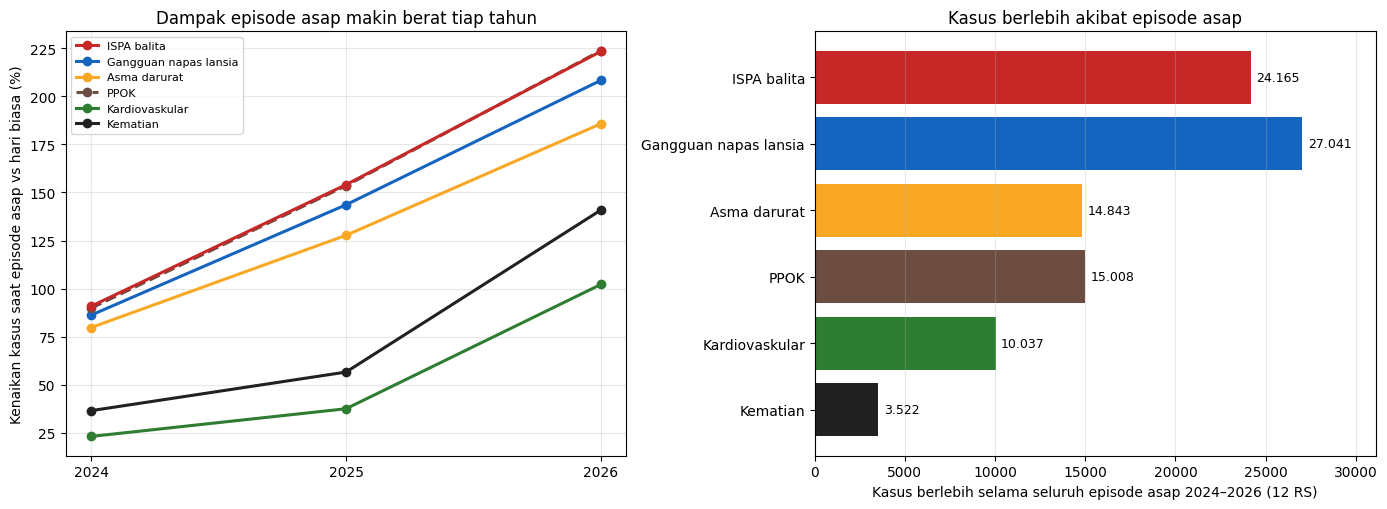

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
tahun_o = epi.groupby(["tahun", "outcome"]).agg(k=("kasus_episode", "sum"), b=("kasus_berlebih", "sum")).reset_index()
tahun_o["pct"] = tahun_o["b"] / (tahun_o["k"] - tahun_o["b"]) * 100
for o in URUT:
    t = tahun_o[tahun_o["outcome"] == o].sort_values("tahun")
    axes[0].plot(t["tahun"], t["pct"], marker="o", lw=2.2, color=WARNA_OUT[o], label=LABEL_OUT[o],
                 ls="--" if o == "copd_admissions" else "-", zorder=3 if o == "resp_admissions_under5" else 2)
axes[0].set_xticks([2024, 2025, 2026])
axes[0].set_xticklabels(["2024", "2025", "2026"])
axes[0].set_ylabel("Kenaikan kasus saat episode asap vs hari biasa (%)")
axes[0].set_title("Dampak episode asap makin berat tiap tahun")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
tot = epi.groupby("outcome")["kasus_berlebih"].sum().loc[URUT]
bars = axes[1].barh([LABEL_OUT[o] for o in URUT], tot.values, color=[WARNA_OUT[o] for o in URUT])
for bb, v in zip(bars, tot.values):
    axes[1].text(v + 300, bb.get_y() + bb.get_height() / 2, f"{v:,.0f}".replace(",", "."), va="center", fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlim(0, tot.max() * 1.15)
axes[1].set_xlabel("Kasus berlebih selama seluruh episode asap 2024–2026 (12 RS)")
axes[1].set_title("Kasus berlebih akibat episode asap")
axes[1].grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "07_T4_episode_dampak.png", dpi=150)
plt.show()

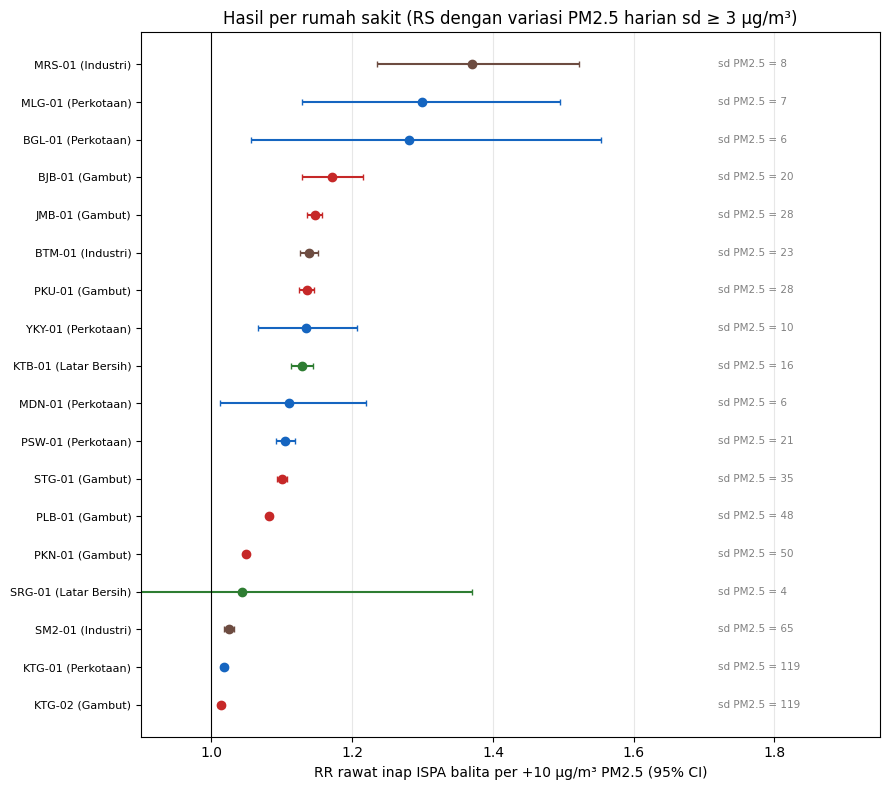

In [34]:
f = rs[rs["outcome"] == "resp_admissions_under5"].copy()
f = f[f["pm25_sd"] >= 3].sort_values("rr")
fig, ax = plt.subplots(figsize=(9, 8))
for yy, (_, r) in enumerate(f.iterrows()):
    ax.errorbar(r["rr"], yy, xerr=[[r["rr"] - r["rr_bawah"]], [r["rr_atas"] - r["rr"]]], fmt="o", color=WARNA_KAT[r["kategori_lokasi"]], capsize=2.5, ms=6)
    ax.text(1.72, yy, f"sd PM2.5 = {r['pm25_sd']:.0f}", va="center", fontsize=7.5, color="grey")
ax.set_yticks(range(len(f)))
ax.set_yticklabels([f"{r.stasiun} ({r.kategori_lokasi})" for r in f.itertuples()], fontsize=8)
ax.axvline(1, color="black", lw=0.8)
ax.set_xlim(0.9, 1.95)
ax.set_xlabel("RR rawat inap ISPA balita per +10 µg/m³ PM2.5 (95% CI)")
ax.set_title("Hasil per rumah sakit (RS dengan variasi PM2.5 harian sd ≥ 3 µg/m³)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "07_T4_forest_per_rs.png", dpi=150)
plt.show()

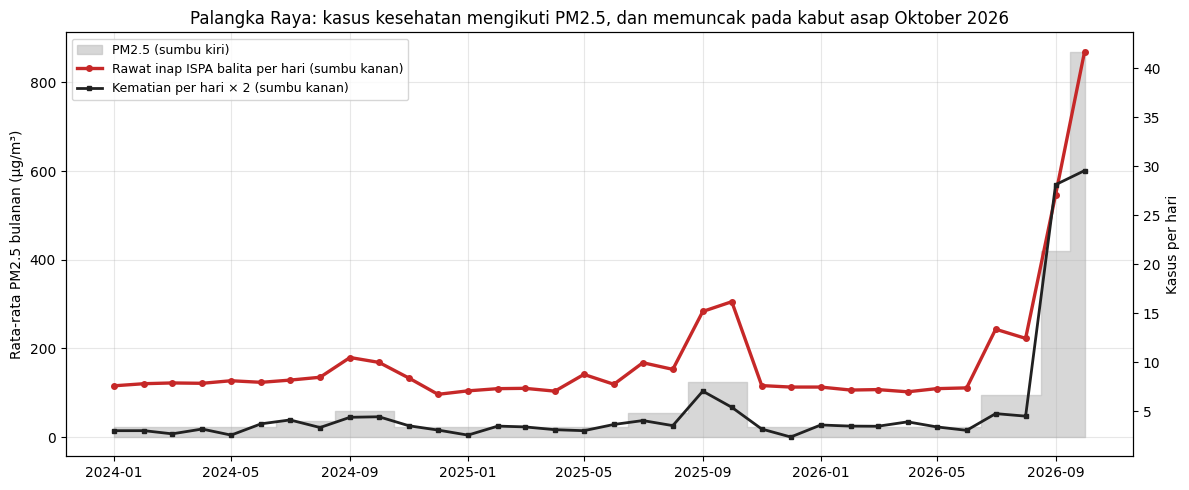

selesai


In [35]:
sehat = pd.read_csv(MART + "fakta_kesehatan_harian.csv", parse_dates=["tanggal"])
g = sehat[sehat["stasiun"] == "KTG-01"].set_index("tanggal")[["pm25", "resp_admissions_under5", "death"]].resample("MS").mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(g.index, g["pm25"], color="#bdbdbd", alpha=0.6, step="mid", label="PM2.5 (sumbu kiri)")
ax.set_ylabel("Rata-rata PM2.5 bulanan (µg/m³)")
ax2 = ax.twinx()
ax2.plot(g.index, g["resp_admissions_under5"], color="#c62828", lw=2.4, marker="o", ms=4, label="Rawat inap ISPA balita per hari (sumbu kanan)")
ax2.plot(g.index, g["death"] * 2, color="#212121", lw=2.0, marker="s", ms=3.5, label="Kematian per hari × 2 (sumbu kanan)")
ax2.set_ylabel("Kasus per hari")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
ax.set_title("Palangka Raya: kasus kesehatan mengikuti PM2.5, dan memuncak pada kabut asap Oktober 2026")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "07_T4_palangka_raya_pm_vs_kasus.png", dpi=150)
plt.show()
print("selesai")